<a href="https://colab.research.google.com/github/lashkami2020/KNN-Customer-Purchase-Prediction/blob/main/KNN_Customer_purchase_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Customer Purchase Prediction Using K-Nearest Neighbors

#Introduction

This project applies the K-Nearest Neighbors (KNN) classification algorithm to predict whether a customer will purchase a product based on two features: Age and Estimated Salary.

KNN is a supervised machine learning algorithm that classifies a new observation based on the classes of its nearest observations in the feature space. Because KNN relies directly on distances between data points, feature scaling is an important preprocessing step.

The main objectives of this project are to:

*   Explore and prepare the customer dataset
*   Separate the predictor variables from the target variable.
*   Split the data into training and testing sets.
*   Standardize the numerical features.
*   Train a KNN classification model.


*   Evaluate the model on unseen test data.
*   Examine different values of K to understand their effect on model performance.
*   Select an appropriate number of neighbors based on classification performance.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("/content/Social_Network_Ads.csv")

In [4]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              400 non-null    int64
 1   EstimatedSalary  400 non-null    int64
 2   Purchased        400 non-null    int64
dtypes: int64(3)
memory usage: 9.5 KB


The dataset contains no missing values in these three variables.

The prediction target is Purchased, while Age and EstimatedSalary are used as input features.

In [18]:
df.isnull().sum()

,0
Age,0
EstimatedSalary,0
Purchased,0


The dataset contains 400 observations and three numerical variables.

In [6]:
df.shape

(400, 3)

In [7]:
df["Purchased"].value_counts()

,count
Purchased,
0,257
1,143


In [8]:
df.columns

Index(['Age', 'EstimatedSalary', 'Purchased'], dtype='object')



##1. Feature and Target Selection

The independent variables and target variable are separated before building the model.

In [9]:
x = df[["Age","EstimatedSalary"]].values
y = df["Purchased"].values

##2. Train-Test Split
The dataset is divided into training and testing subsets.The training set is used to build the KNN model, while the test set is kept separate to evaluate how well the trained model performs on unseen observations.

Using random_state=42 makes the split reproducible, meaning the same training and testing observations are obtained each time the code is executed.

In [10]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size =0.2, random_state = 42)


##3. Feature Scaling

KNN determines neighbors using distances between observations. Since Age and EstimatedSalary have substantially different numerical scales, the features are standardized before fitting the model.The scaler is fitted only on the training data. The same fitted scaler is then applied to the test data. This prevents information from the test set from leaking into the training process.

In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(x_train)
x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)



##4. K-Nearest Neighbors Classification

KNN assigns a class to an observation based on the classes of its nearest neighbors.

In [12]:
k =5
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = k).fit(x_train, y_train)
y_pred = knn.predict(x_test)

In [13]:
from sklearn import metrics
print("Train set Accuracy: " , metrics.accuracy_score(y_train, knn.predict(x_train)))
print("Test set Accuracy: " , metrics.accuracy_score(y_test, y_pred))

Train set Accuracy:  0.909375
Test set Accuracy:  0.9125


##5. Testing Different Values of K
To investigate the effect of the number of neighbors, K values from 1 to 29 are evaluated.

In [14]:
ks = 30
mean_acc =np.zeros((ks-1))
std =np.zeros((ks-1))
for n in range(1,ks):
  knn = KNeighborsClassifier(n_neighbors = n).fit(x_train, y_train)
  y_pred = knn.predict(x_test)
  mean_acc[n-1] = metrics.accuracy_score(y_test, y_pred)
  std[n-1] = np.std(y_pred == y_test)/np.sqrt(y_pred.shape[0])
mean_acc

array([0.8375, 0.8625, 0.925 , 0.925 , 0.9125, 0.9   , 0.9375, 0.925 ,
       0.9375, 0.925 , 0.925 , 0.925 , 0.925 , 0.925 , 0.925 , 0.925 ,
       0.925 , 0.925 , 0.925 , 0.9375, 0.925 , 0.9375, 0.9375, 0.9375,
       0.9375, 0.9375, 0.9375, 0.9375, 0.9375])

In [15]:
print("Best accuracy:", mean_acc.max())
print("Best K:", mean_acc.argmax() + 1)

Best accuracy: 0.9375
Best K: 7


##6. Accuracy vs. Number of Neighbors

The relationship between K and classification accuracy can be visualized as follows:

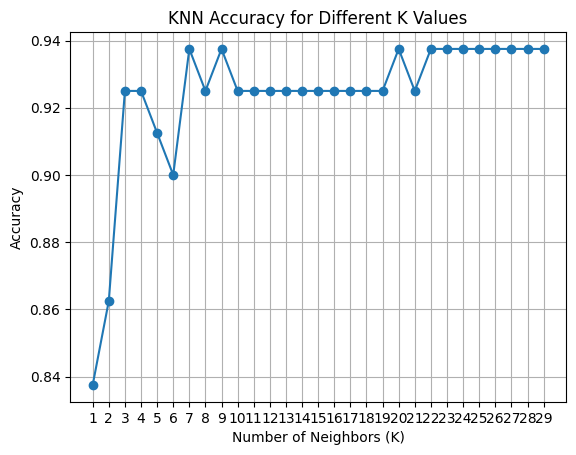

In [16]:
import matplotlib.pyplot as plt

plt.plot(range(1, ks), mean_acc, marker='o')

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy for Different K Values')

plt.xticks(range(1, ks))
plt.grid()

plt.show()

The plot helps identify how sensitive the classifier is to the choice of K. In this experiment, accuracy increases substantially after the smallest K values and then remains relatively stable, with several configurations reaching 93.75% accuracy.

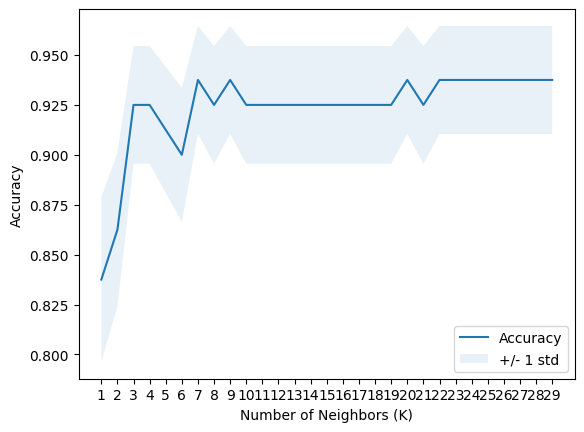

In [17]:
plt.plot(range(1, ks), mean_acc)

plt.fill_between(
    range(1, ks),
    mean_acc - 1 * std,
    mean_acc + 1 * std,
    alpha=0.10
)

plt.legend(('Accuracy', '+/- 1 std'))

plt.ylabel('Accuracy')
plt.xlabel('Number of Neighbors (K)')
plt.xticks(range(1, ks))

plt.show()

For a more complete classification assessment, the model can also be evaluated using a confusion matrix, precision, recall, and F1-score.

In [19]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[49  3]
 [ 2 26]]
              precision    recall  f1-score   support

           0       0.96      0.94      0.95        52
           1       0.90      0.93      0.91        28

    accuracy                           0.94        80
   macro avg       0.93      0.94      0.93        80
weighted avg       0.94      0.94      0.94        80



##Conclusion

This project demonstrated the application of the K-Nearest Neighbors algorithm to a binary customer purchase prediction problem.

The dataset contained 400 observations, with Age and EstimatedSalary used to predict the Purchased outcome. Because KNN is distance-based, the predictor variables were standardized using statistics learned exclusively from the training data.

Testing K values from 1 through 29 showed that the model reached a maximum observed test accuracy of 93.75%, with multiple K values producing the same result. The first occurrence of this maximum was at K = 7.